# Region sizing for spatially-localised descriptors

Picks the region grid for regional descriptors, from your actual labels.

**The question.** A regional centroid is only informative if its region contains *one*
connected piece of the structure. If a region straddles two limbs of a curved sheet, its
centroid lands in the void between them and becomes an actively misleading target — in a
synthetic W test, 2x2x2 octants scored *worse* than no regions at all (0.207 vs 0.235 Dice),
while 4x4x4 scored 0.320.

So the rule is **region size must be smaller than the curvature wavelength**, and this
notebook measures that wavelength per class, on both patch branches.

**What it reports**
1. Occupancy — how many regions hold enough GT mass to carry a centroid/spread constraint.
2. Centroid-in-structure — how far each regional centroid falls from the structure it
   summarises. This is the direct test of the rule above.
3. Curvature wavelength — how fast the structure's midline moves, versus region size.
4. Visual check, with the grid and regional centroids drawn on a slice.

Run top to bottom. Only the paths in the next cell should need changing.

In [2]:
%pip install nibabel scipy

  Using cached nibabel-5.4.2-py3-none-any.whl.metadata (8.9 kB)
Using cached nibabel-5.4.2-py3-none-any.whl (3.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [nibabel]m1/2 [nibabel]
Note: you may need to restart the kernel to use updated packages.


In [3]:
# ---- paths: change these two if your data lives elsewhere --------------------
IMAGES_DIR = "/Users/ioana/Desktop/shape_analysis/data/OAI_ZIB_DESS"
LABELS_DIR = "/Users/ioana/Desktop/shape_analysis/data/OAI"
REPO       = "/Users/ioana/Desktop/Phd/meunet-shape-supervision-oai/meunet_raw"

N_CASES    = 2            # how many scans to analyse
PATCH_SIZE = (200, 200, 200)
EXPAND     = 2.0
FIXED_CENTER = (188, 200, 77)   # the `fixed_center: auto` value for this dataset
MIN_MASS   = 20           # voxels below which a region cannot carry centroid/spread
GRIDS      = [(2,2,2), (4,4,4), (8,8,8)]

CLASSES = {1: "femur", 2: "fem.cart", 3: "tibia", 4: "tib.cart"}

import sys, warnings
sys.path.insert(0, REPO)
warnings.filterwarnings("ignore")

import numpy as np, torch, torch.nn.functional as F, nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import ndimage

# the repo's own patch geometry, so this matches training exactly
from data.dataset_oai_raw_fixedpatch import _compute_patch_bounds, _sample_fixed_patch_pair

print("torch", torch.__version__, "| nibabel", nib.__version__)


def half_thickness(mask):
    """Mean interior distance-to-background = half the local thickness, in voxels.

    A column sum would measure EXTENT, not thickness: a row tangent to a curved
    sheet holds many voxels while the sheet stays 2-3 voxels thick. The distance
    transform measures the thing we actually mean.
    """
    if not mask.any():
        return np.nan
    return float(ndimage.distance_transform_edt(mask)[mask].mean())

torch 2.5.1 | nibabel 5.4.2


## 1. Load cases and build the two patch branches

STD is supervised through `logit1` at full patch resolution; EXP through `logit2`, one
decoder level up and therefore half resolution. Regions act on those shapes, so the labels
are resampled to each branch's own supervision shape before anything is measured.

In [4]:
stems = [p.name.replace(".nii.gz", "").replace(".nii", "")
         for p in sorted(Path(IMAGES_DIR).glob("*.nii*"))][:N_CASES]
print("cases:", stems)

def resize_nn(a, shape):
    if tuple(a.shape) == tuple(shape):
        return a
    t = torch.as_tensor(a)[None, None].float()
    return F.interpolate(t, size=tuple(shape), mode="nearest")[0, 0].numpy().astype(np.int16)

patches = {}   # (stem, branch) -> label array at that branch's supervision shape
for stem in stems:
    lbl = nib.load(f"{LABELS_DIR}/{stem}_segmentation.nii.gz").get_fdata().astype(np.int16)
    img = np.zeros_like(lbl, dtype=np.float32)            # image not needed for geometry
    std_i, std_l, exp_i, exp_l = _sample_fixed_patch_pair(
        img, lbl, PATCH_SIZE, EXPAND, FIXED_CENTER)
    # supervision shapes: STD = the crop itself, EXP = half of patch_size (logit2)
    std_shape = tuple(std_l.shape)
    exp_shape = tuple(s // 2 for s in exp_l.shape)
    patches[(stem, "std")] = resize_nn(std_l, std_shape)
    patches[(stem, "exp")] = resize_nn(exp_l, exp_shape)
    print(f"  {stem}: volume {lbl.shape} -> STD {std_shape}, EXP {exp_shape}")

cases: ['9001104_R', '9002430_R']
  9001104_R: volume (384, 384, 160) -> STD (200, 200, 160), EXP (100, 100, 100)
  9002430_R: volume (384, 384, 160) -> STD (200, 200, 160), EXP (100, 100, 100)


## 2. Occupancy — how many regions can carry a constraint

A region whose GT mass is below `MIN_MASS` cannot support a centroid or spread target
(the centroid of three voxels is noise). Those regions keep only a volume target of ~0.

Watch the thin classes: if most regions are unusable at a given grid, that grid is spending
its constraint budget on volume-only terms, which the W experiment showed buy very little.

In [5]:
def blocks(mask, grid):
    """mask (D,H,W) bool -> (R, dz,dy,dx) float blocks, plus the block shape."""
    D, H, W = mask.shape
    gz, gy, gx = grid
    dz, dy, dx = D // gz, H // gy, W // gx
    m = mask[:gz*dz, :gy*dy, :gx*dx].astype(np.float32)
    mb = (m.reshape(gz, dz, gy, dy, gx, dx)
            .transpose(0, 2, 4, 1, 3, 5)
            .reshape(gz*gy*gx, dz, dy, dx))
    return mb, (dz, dy, dx)

rows = []
for (stem, br), lab in patches.items():
    for c, name in CLASSES.items():
        mask = (lab == c)
        for g in GRIDS:
            mb, bs = blocks(mask, g)
            cnt = mb.sum((1, 2, 3))
            rows.append(dict(case=stem, branch=br, cls=name, grid="x".join(map(str, g)),
                             block=bs, regions=len(cnt),
                             nonempty=int((cnt > 0).sum()),
                             usable=int((cnt >= MIN_MASS).sum()),
                             usable_pct=100.0*int((cnt >= MIN_MASS).sum())/len(cnt),
                             total_vox=int(cnt.sum())))

hdr = f"{'case':12s}{'br':5s}{'class':10s}{'grid':8s}{'block':16s}{'regions':>8s}{'usable':>8s}{'usable%':>9s}{'GT vox':>9s}"
print(hdr); print("-"*len(hdr))
for r in rows:
    print(f"{r['case'][:11]:12s}{r['branch']:5s}{r['cls']:10s}{r['grid']:8s}"
          f"{str(r['block']):16s}{r['regions']:8d}{r['usable']:8d}{r['usable_pct']:8.0f}%{r['total_vox']:9d}")

case        br   class     grid    block            regions  usable  usable%   GT vox
-------------------------------------------------------------------------------------
9001104_R   std  femur     2x2x2   (100, 100, 80)         8       8     100%  1661854
9001104_R   std  femur     4x4x4   (50, 50, 40)          64      52      81%  1661854
9001104_R   std  femur     8x8x8   (25, 25, 20)         512     241      47%  1661854
9001104_R   std  fem.cart  2x2x2   (100, 100, 80)         8       8     100%   121393
9001104_R   std  fem.cart  4x4x4   (50, 50, 40)          64      37      58%   121393
9001104_R   std  fem.cart  8x8x8   (25, 25, 20)         512     106      21%   121393
9001104_R   std  tibia     2x2x2   (100, 100, 80)         8       4      50%   441714
9001104_R   std  tibia     4x4x4   (50, 50, 40)          64      16      25%   441714
9001104_R   std  tibia     8x8x8   (25, 25, 20)         512      78      15%   441714
9001104_R   std  tib.cart  2x2x2   (100, 100, 80)     

## 3. Centroid-in-structure — the decisive test

For every usable region, take the GT centroid of that class inside the region and measure how
far it lands from the nearest voxel of the class, in voxels (via a distance transform).

* **distance ~ 0** — the region holds one coherent piece; its centroid is a meaningful target.
* **distance large** — the region straddles separate limbs and the centroid sits in the void.
  Constraining the prediction toward that point pulls mass into empty space.

The yardstick is the structure's own **half-thickness**, not the block size: a centroid 3 voxels
off is harmless inside a solid bone and fatal on a 3-voxel-thick cartilage sheet. `d/half-thick`
under 1 means the centroid sits inside the structure; above 2 it is in the void.

In [6]:
def centroid_report(mask, grid, min_mass=MIN_MASS):
    """Per-region: GT centroid distance to the nearest voxel of the structure."""
    if not mask.any():
        return None
    edt = ndimage.distance_transform_edt(~mask)        # distance to nearest True voxel
    D, H, W = mask.shape
    gz, gy, gx = grid
    dz, dy, dx = D // gz, H // gy, W // gx
    zc = np.arange(dz)[:, None, None]
    yc = np.arange(dy)[None, :, None]
    xc = np.arange(dx)[None, None, :]
    mb, _ = blocks(mask, grid)
    dists = []
    for r in range(mb.shape[0]):
        b = mb[r]; m = b.sum()
        if m < min_mass:
            continue
        cz = float((b*zc).sum()/m); cy = float((b*yc).sum()/m); cx = float((b*xc).sum()/m)
        iz, iy, ix = np.unravel_index(r, (gz, gy, gx))      # region origin
        gzz = int(round(cz)) + iz*dz
        gyy = int(round(cy)) + iy*dy
        gxx = int(round(cx)) + ix*dx
        gzz = min(max(gzz, 0), D-1); gyy = min(max(gyy, 0), H-1); gxx = min(max(gxx, 0), W-1)
        dists.append(float(edt[gzz, gyy, gxx]))
    return np.array(dists) if dists else None

# Normalised by HALF-THICKNESS: the question is whether the centroid lands inside
# the structure, so the sheet's own thickness is the yardstick. Normalising by block
# size instead flatters every grid, because blocks are far larger than the sheet.
hdr = (f"{'case':12s}{'br':5s}{'class':10s}{'grid':8s}{'n':>5s}{'mean d':>9s}{'median':>9s}"
       f"{'p90':>8s}{'max':>8s}{'half-thick':>12s}{'d/half-thick':>14s}  verdict")
print(hdr); print("-"*len(hdr))
for (stem, br), lab in patches.items():
    for c, name in CLASSES.items():
        mask = (lab == c)
        for g in GRIDS:
            d = centroid_report(mask, g)
            if d is None:
                print(f"{stem[:11]:12s}{br:5s}{name:10s}{'x'.join(map(str,g)):8s}"
                      f"{'--':>5s}{'(no usable region)':>48s}")
                continue
            ht = half_thickness(mask)
            rel = d.mean()/max(ht, 1e-6)
            verdict = "inside" if rel < 1 else ("edge" if rel < 2 else "IN VOID")
            print(f"{stem[:11]:12s}{br:5s}{name:10s}{'x'.join(map(str,g)):8s}{len(d):5d}"
                  f"{d.mean():9.2f}{np.median(d):9.2f}{np.percentile(d,90):8.2f}{d.max():8.2f}"
                  f"{ht:12.2f}{rel:14.2f}  {verdict}")

case        br   class     grid        n   mean d   median     p90     max  half-thick  d/half-thick  verdict
-------------------------------------------------------------------------------------------------------------
9001104_R   std  femur     2x2x2       8     0.00     0.00    0.00    0.00       13.48          0.00  inside
9001104_R   std  femur     4x4x4      52     0.00     0.00    0.00    0.00       13.48          0.00  inside
9001104_R   std  femur     8x8x8     241     0.00     0.00    0.00    0.00       13.48          0.00  inside
9001104_R   std  fem.cart  2x2x2       8     3.04     2.34    7.02    7.07        1.64          1.85  edge
9001104_R   std  fem.cart  4x4x4      37     0.33     0.00    1.00    1.41        1.64          0.20  inside
9001104_R   std  fem.cart  8x8x8     106     0.05     0.00    0.00    1.41        1.64          0.03  inside
9001104_R   std  tibia     2x2x2       4     0.00     0.00    0.00    0.00       11.30          0.00  inside
9001104_R   std  ti

## 4. Curvature wavelength

Section 3 asked whether a regional centroid is a *valid* target. This asks how much it
**throws away**: slide along each axis, track where the structure's midline sits, and compare
how far it moves inside one region against the sheet's own thickness.

* **ratio < 1** — the region holds a near-flat piece; one centroid captures it.
* **ratio 1-4** — mild curvature inside the region.
* **ratio > 4** — the centroid is still a real point on the structure, but it is standing in
  for a long sweep of curve, so the constraint says much less than it appears to.

The two sections can disagree, and that is informative: a centroid can sit squarely on a curved
sheet while summarising a great deal of curvature. Section 3 decides whether a grid is *safe*;
section 4 decides whether it is *useful*.

In [7]:
def half_thickness(mask):
    """Mean interior distance-to-background = half the local thickness, in voxels.

    A column sum would measure EXTENT, not thickness: a row lying tangent to a
    curved sheet contains many voxels while the sheet stays 2-3 voxels thick. The
    distance transform measures the thing we actually mean.
    """
    if not mask.any():
        return np.nan
    return float(ndimage.distance_transform_edt(mask)[mask].mean())


def midline_profile(mask, axis):
    """Mean position of the mask in the plane perpendicular to `axis`, per slice."""
    prof = []
    for i in range(mask.shape[axis]):
        sl = np.take(mask, i, axis=axis)
        if sl.sum() < 3:
            prof.append(np.nan); continue
        prof.append(np.argwhere(sl)[:, 0].mean())
    return np.array(prof)

print(f"{'case':12s}{'br':5s}{'class':10s}{'axis':6s}{'grid':8s}{'win':>5s}"
      f"{'midline sd':>12s}{'half-thick':>12s}{'ratio':>8s}  verdict")
print("-"*96)
for (stem, br), lab in list(patches.items()):
    for c, name in CLASSES.items():
        mask = (lab == c)
        if mask.sum() < 50:
            continue
        for axis in (0, 1, 2):
            prof = midline_profile(mask, axis)
            ok = ~np.isnan(prof)
            if ok.sum() < 8:
                continue
            ht = half_thickness(mask)
            for g in GRIDS:
                win = mask.shape[axis]//g[axis]
                sds = [np.nanstd(prof[s:s+win]) for s in range(0, len(prof)-win+1, max(win//2,1))
                       if np.isfinite(prof[s:s+win]).sum() >= 3]
                if not sds:
                    continue
                sd = float(np.nanmean(sds)); ratio = sd/max(ht, 1e-6)
                # How much curve one centroid is being asked to stand for, in units of
                # the sheet's own thickness. This is an INFORMATION measure, not a
                # validity one -- section 3 already established whether the target is
                # a real point on the structure. A high ratio means the target is valid
                # but coarse: one point summarising a long sweep of curve.
                verdict = ("flat piece" if ratio < 1 else
                           "mild curve" if ratio < 4 else
                           "centroid smears across curve")
                print(f"{stem[:11]:12s}{br:5s}{name:10s}{'zyx'[axis]:6s}"
                      f"{'x'.join(map(str,g)):8s}{win:5d}{sd:12.2f}{ht:12.2f}{ratio:8.2f}  {verdict}")
        print()

case        br   class     axis  grid      win  midline sd  half-thick   ratio  verdict
------------------------------------------------------------------------------------------------
9001104_R   std  femur     z     2x2x2     100        7.59       13.48    0.56  flat piece
9001104_R   std  femur     z     4x4x4      50        4.00       13.48    0.30  flat piece
9001104_R   std  femur     z     8x8x8      25        2.38       13.48    0.18  flat piece
9001104_R   std  femur     y     2x2x2     100        6.40       13.48    0.47  flat piece
9001104_R   std  femur     y     4x4x4      50        3.20       13.48    0.24  flat piece
9001104_R   std  femur     y     8x8x8      25        1.74       13.48    0.13  flat piece
9001104_R   std  femur     x     2x2x2      80       14.26       13.48    1.06  mild curve
9001104_R   std  femur     x     4x4x4      40        8.56       13.48    0.63  flat piece
9001104_R   std  femur     x     8x8x8      20        5.14       13.48    0.38  flat pi

## 5. Visual check

The slice holding the most of each class, with the region grid drawn on top and every usable
region's centroid marked: **green** where the centroid sits on the structure, **red** where it
falls in the void. Red dots are the misleading constraints — a grid producing many of them will
pull predicted mass into empty space.

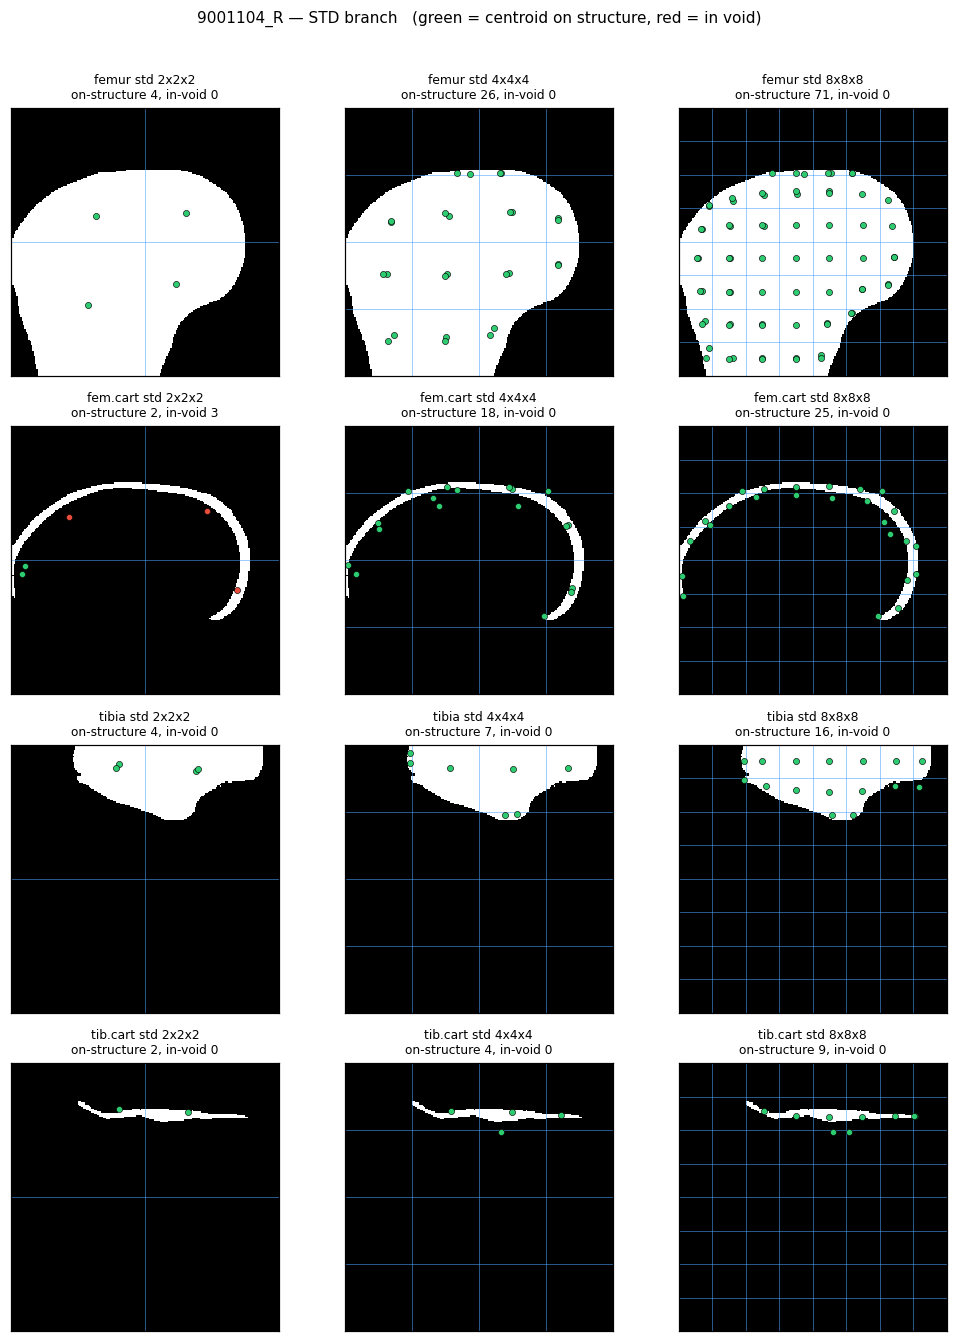

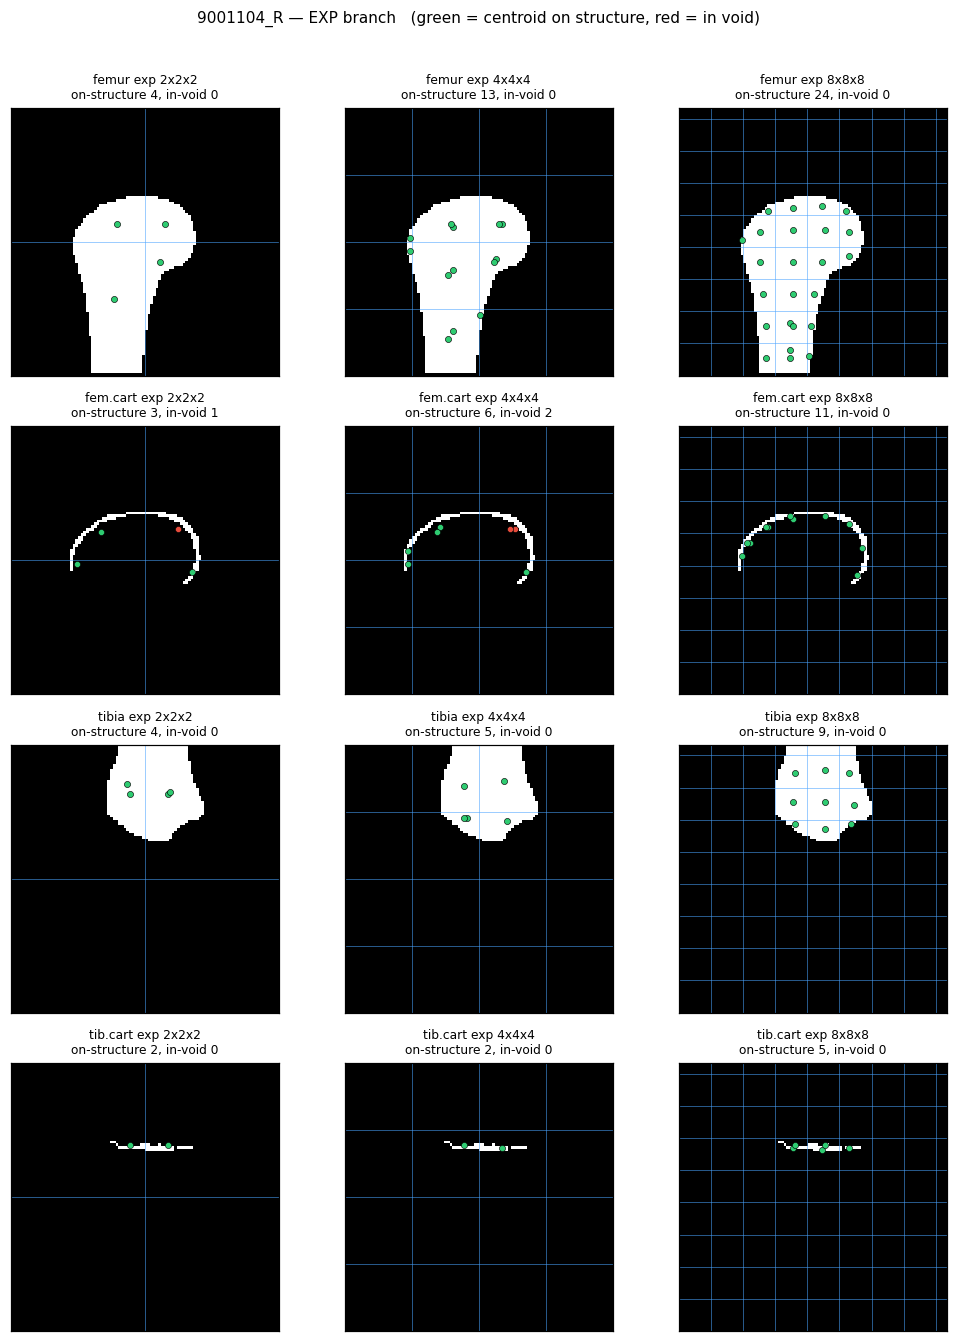

In [8]:
def best_slice(mask, axis=2):
    counts = [np.take(mask, i, axis=axis).sum() for i in range(mask.shape[axis])]
    return int(np.argmax(counts))

def draw(stem, branch, cls, grid, axis=2, ax=None):
    lab = patches[(stem, branch)]
    mask = (lab == cls)
    if not mask.any():
        return
    sl = best_slice(mask, axis)
    img = np.take(mask, sl, axis=axis).T
    ax.imshow(img, cmap="gray", origin="lower", interpolation="nearest")
    D, H, W = mask.shape
    gz, gy, gx = grid
    dz, dy, dx = D//gz, H//gy, W//gx
    shown = [a for a in (0,1,2) if a != axis]
    n0, n1 = mask.shape[shown[0]], mask.shape[shown[1]]
    s0 = (dz, dy, dx)[shown[0]]; s1 = (dz, dy, dx)[shown[1]]
    for v in range(0, n0+1, s0): ax.axvline(v-0.5, color="#4aa3ff", lw=0.5, alpha=0.7)
    for v in range(0, n1+1, s1): ax.axhline(v-0.5, color="#4aa3ff", lw=0.5, alpha=0.7)
    edt = ndimage.distance_transform_edt(~mask)
    mb, _ = blocks(mask, grid)
    zc = np.arange(dz)[:,None,None]; yc = np.arange(dy)[None,:,None]; xc = np.arange(dx)[None,None,:]
    ng = gr = 0
    for r in range(mb.shape[0]):
        b = mb[r]; m = b.sum()
        if m < MIN_MASS: continue
        iz, iy, ix = np.unravel_index(r, (gz, gy, gx))
        g_ = [int(round(float((b*zc).sum()/m)))+iz*dz,
              int(round(float((b*yc).sum()/m)))+iy*dy,
              int(round(float((b*xc).sum()/m)))+ix*dx]
        g_ = [min(max(v,0), s-1) for v, s in zip(g_, mask.shape)]
        if abs(g_[axis]-sl) > (dz, dy, dx)[axis]//2:   # only regions near this slice
            continue
        d = edt[tuple(g_)]
        col = "#2ecc71" if d <= 1.5 else "#e74c3c"
        ax.plot(g_[shown[0]], g_[shown[1]], "o", color=col, ms=4, mec="k", mew=0.4)
        ng += (d <= 1.5); gr += (d > 1.5)
    ax.set_title(f"{CLASSES[cls]} {branch} {'x'.join(map(str,grid))}\n"
                 f"on-structure {ng}, in-void {gr}", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

stem = stems[0]
for branch in ("std", "exp"):
    fig, axes = plt.subplots(len(CLASSES), len(GRIDS),
                             figsize=(3.1*len(GRIDS), 3.1*len(CLASSES)), dpi=110)
    for i, c in enumerate(CLASSES):
        for j, g in enumerate(GRIDS):
            draw(stem, branch, c, g, ax=axes[i, j])
    fig.suptitle(f"{stem} — {branch.upper()} branch   (green = centroid on structure, red = in void)",
                 fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

## 6. Midline profiles

The raw curves behind section 4. A flat profile is a structure a coarse grid can summarise; an
oscillating one needs regions narrower than the oscillation. Vertical lines mark region
boundaries for each candidate grid — a region spanning a full peak-to-trough swing is the
failure case.

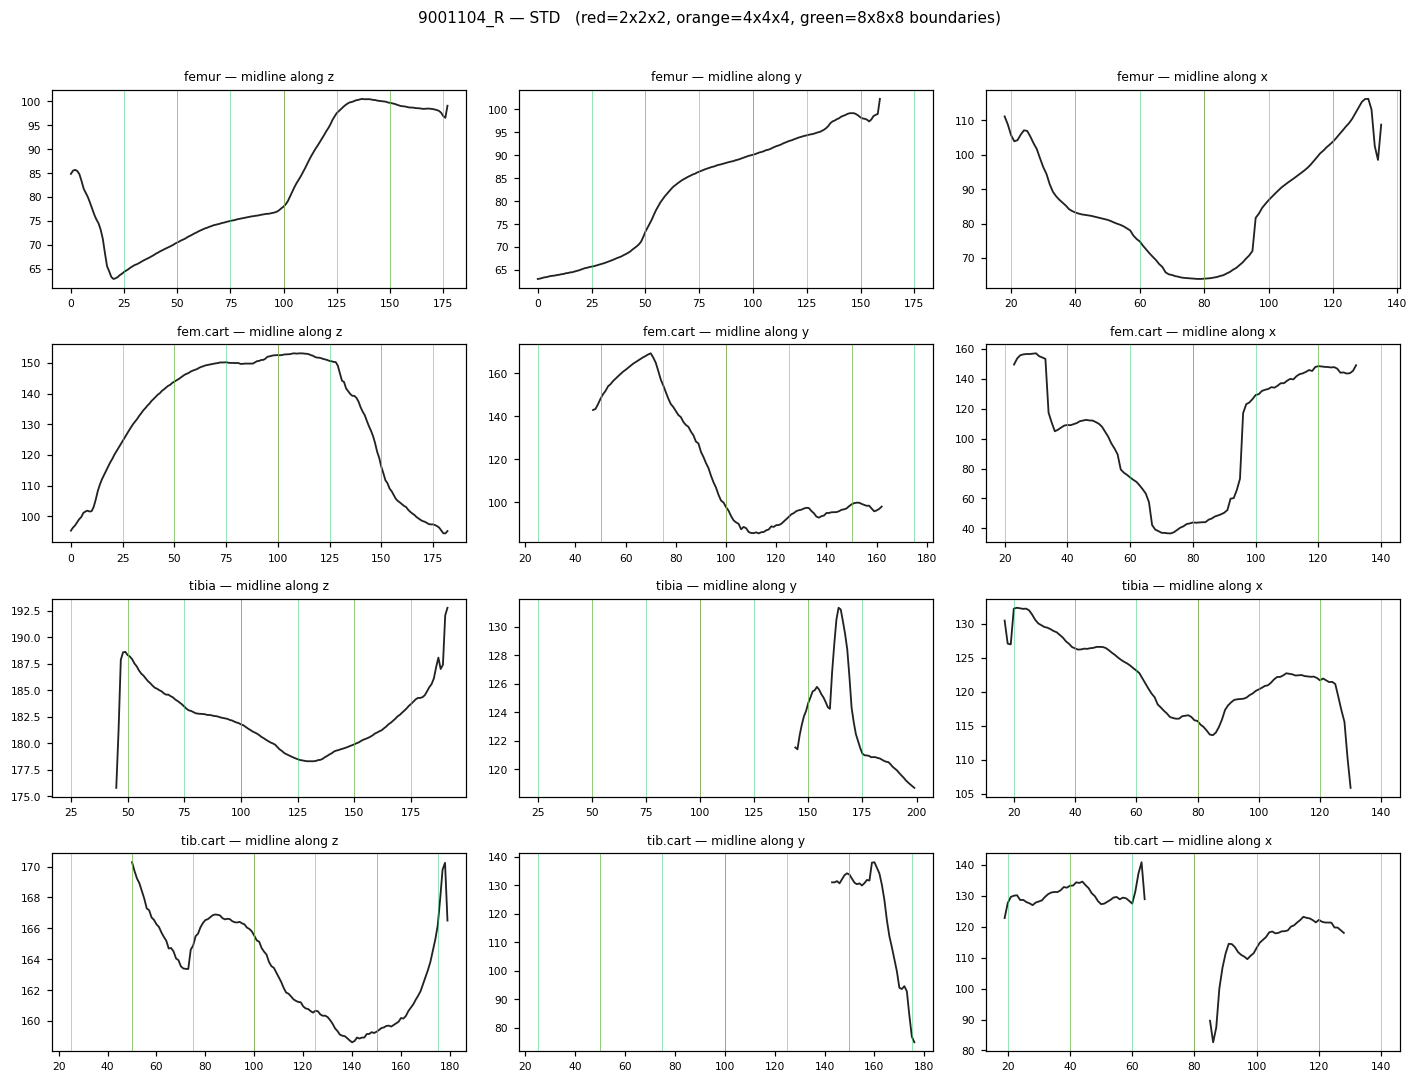

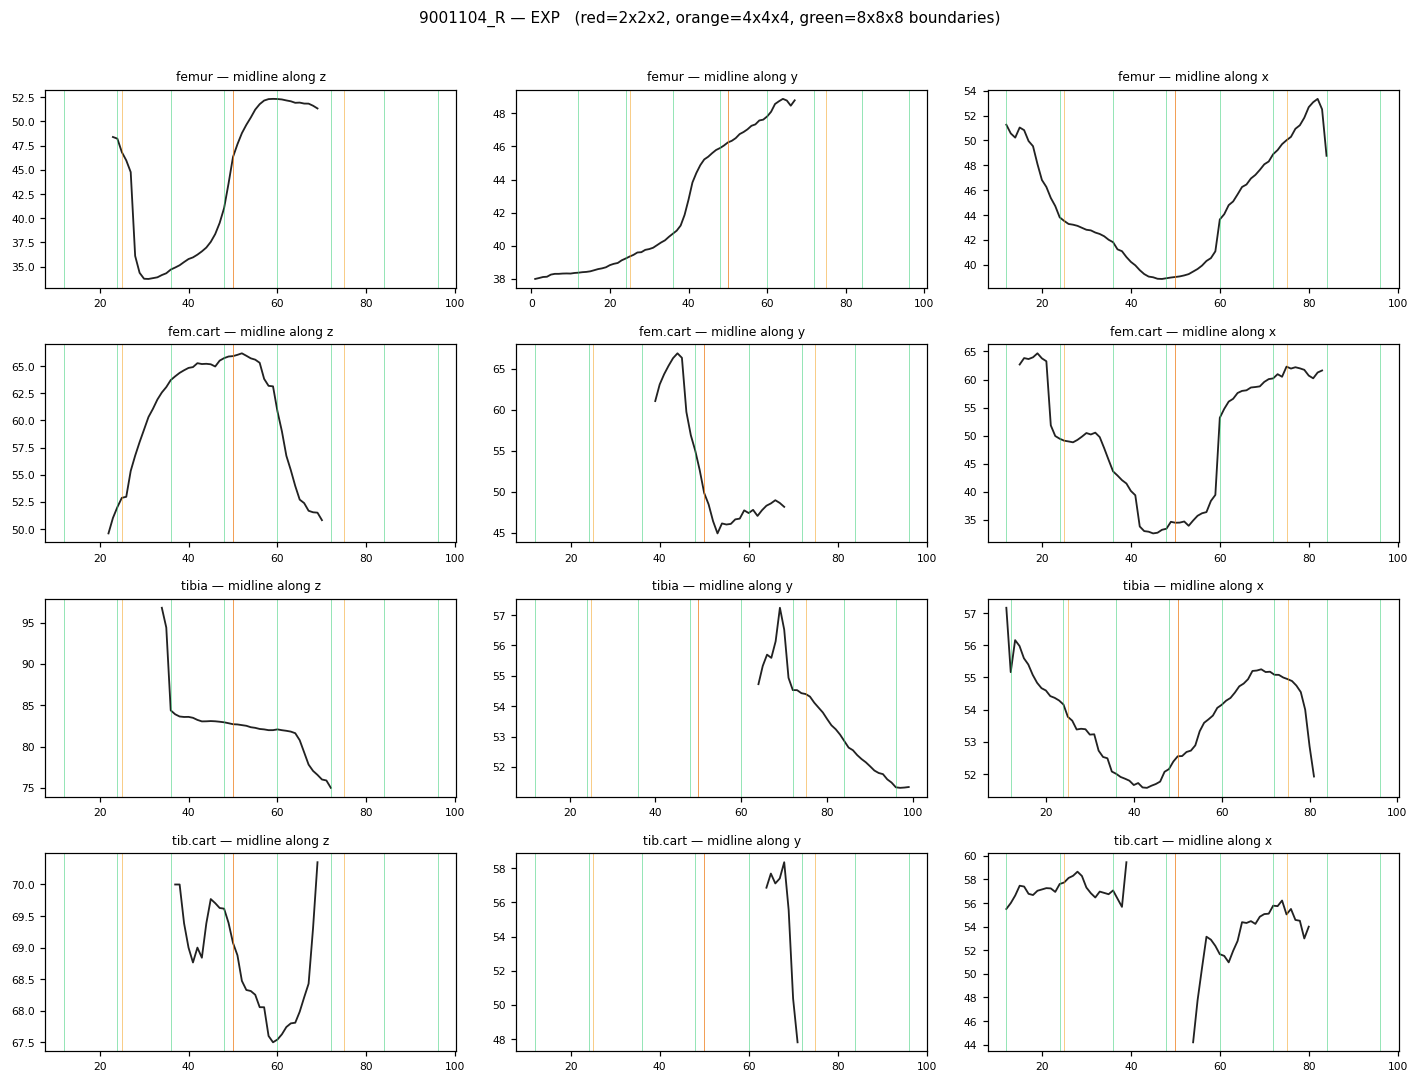

In [11]:
stem = stems[0]
for branch in ("std", "exp"):
    fig, axes = plt.subplots(len(CLASSES), 3, figsize=(13, 2.5*len(CLASSES)), dpi=110)
    for i, c in enumerate(CLASSES):
        mask = (patches[(stem, branch)] == c)
        for axis in (0, 1, 2):
            ax = axes[i, axis]
            if mask.sum() < 50:
                ax.set_axis_off(); continue
            prof = midline_profile(mask, axis)
            ax.plot(prof, color="#222", lw=1.2)
            for g, col in zip(GRIDS, ("#e74c3c", "#f39c12", "#2ecc71")):
                step = mask.shape[axis]//g[axis]
                for v in range(step, mask.shape[axis], step):
                    ax.axvline(v, color=col, lw=0.6, alpha=0.55)
            ax.set_title(f"{CLASSES[c]} — midline along {'zyx'[axis]}", fontsize=8)
            ax.tick_params(labelsize=7)
    fig.suptitle(f"{stem} — {branch.upper()}   (red=2x2x2, orange=4x4x4, green=8x8x8 boundaries)",
                 fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

## How to read the result

Two separate questions, in order:

1. **Is the grid safe?** Section 3, `d/half-thick` under ~1 for every class. Above 2 the
   regional centroids sit in the void and will pull predicted mass into empty space — the
   failure mode that made 2x2x2 octants score *worse* than no regions at all on a synthetic W.
2. **Is it useful?** Section 4. Even a safe grid can be too coarse to say anything, with one
   centroid standing in for a long sweep of curve.

Pick the coarsest grid that is safe on every class and useful on the cartilage ones, then
confirm against section 5 (few red dots) and section 6 (region boundaries falling inside, not
across, the swings of the midline).

Things worth checking specifically:

* **Bones vs cartilage.** Bones are solid, with a half-thickness of 10+ voxels, so their
  centroids sit inside the structure at any grid and regions should be harmless for them. If a
  bone ever reads `IN VOID`, suspect the grid rather than the class.
* **STD vs EXP.** EXP is supervised at `logit2`, half of a patch that is itself the whole volume
  downsampled, so cartilage there survives as only ~1500-3000 voxels. Expect far fewer usable
  regions on EXP; if most are unusable, enable regions on STD only.
* **Anisotropy.** Everything is reported per axis. If one axis needs 8 divisions while the
  others are fine at 2, use an anisotropic grid rather than paying for 8x8x8 everywhere — the
  constraint count, and the cost, scale as the product.